# Satisfacción estudiantil: Pandas, SQLite, Matplotlib y Bokeh
##### Maestría en Inteligencia Artificial Aplicada - Herramientas para IA - Trabajo final - Rodrigo Santillana - Wilbert Zevallos

Encuesta de satisfacción de estudiantes de pregrado de una universidad. Los datos están **anonimizados**: no hay nombres, las preguntas se agruparon en dimensiones y los programas de estudio se agruparon en áreas de conocimiento.

| Dataset | Origen | Contenido |
|---|---|---|
| Dataset 1 | `data/respuestas_encuesta.csv` | Respuestas de la encuesta: una calificación de 1 a 5 por dimensión. |
| Dataset 2 | `data/encuesta.db` (SQLite) | Perfil del estudiante: sexo, rango de edad, etapa de la carrera, procedencia y área. |

Los datos se descargan desde Kaggle, así que el notebook funciona igual en Jupyter Lab y en Google Colab. El notebook crea la base de datos con los archivos SQL, une los dos datasets por la columna `id_encuestado`, analiza la tabla unida y genera los gráficos.

## 1. Librerías y descarga de los datos

In [5]:
import os
import sqlite3
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Descargamos desde Kaggle los tres archivos del proyecto: el CSV con las respuestas y los dos archivos SQL de la base de datos. `kagglehub` los guarda en una carpeta de la computadora (o de Colab) y devuelve su ubicación.

In [6]:
ruta = kagglehub.dataset_download("rodrisantillana/encuesta-satisfaccion-estudiantil")
ruta

'C:\\Users\\acalidad07\\.cache\\kagglehub\\datasets\\rodrisantillana\\encuesta-satisfaccion-estudiantil\\versions\\1'

In [7]:
os.listdir(ruta)

['01_crear_tablas.sql', '02_insertar_datos.sql', 'respuestas_encuesta.csv']

Los resultados del notebook (la base de datos, el dataset final y los gráficos) se guardan en las carpetas `data` e `img`. Si no existen, por ejemplo en Colab, se crean.

In [8]:
os.makedirs("data", exist_ok=True)
os.makedirs("img", exist_ok=True)

## 2. Dataset 1: archivo CSV
Leemos las respuestas de la encuesta desde la carpeta descargada y observamos el DataFrame.

In [9]:
respuestas = pd.read_csv(f"{ruta}/respuestas_encuesta.csv")
respuestas

,id_encuestado,plan_estudios,evaluacion_aprendizaje,docentes,infraestructura,recursos_virtuales,responsabilidad_social,investigacion_formativa,bienestar_universitario,procesos_academicos,tutoria,comedor,practicas_preprofesionales,realiza_practicas,considero_desertar
0,1698,3.2,3.9,3.57,3.67,4.00,3.75,4.00,3.91,3.75,4.0,4.00,NaN,No,NaN
1,2035,5.0,4.5,4.57,4.50,4.71,4.50,4.50,4.27,4.56,4.5,4.67,NaN,No,Si
2,7908,4.6,5.0,5.00,5.00,5.00,4.25,5.00,2.45,3.56,4.0,3.00,5.0,Si,Si
3,4405,3.0,3.4,3.14,3.42,3.00,3.00,3.00,2.71,3.00,3.5,3.67,NaN,No,No
4,4382,4.0,4.0,3.71,4.00,4.00,4.00,4.00,4.00,4.00,4.0,4.00,NaN,No,Si
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8751,4789,5.0,5.0,4.86,4.33,4.00,5.00,4.25,4.64,4.33,5.0,5.00,NaN,No,NaN
8752,1799,4.0,4.0,3.86,3.67,4.00,3.00,3.25,4.62,2.67,3.5,2.33,NaN,No,NaN
8753,5174,4.0,4.0,4.00,4.00,4.00,4.00,3.50,3.18,3.00,3.0,3.00,NaN,No,No
8754,529,3.8,3.8,4.00,4.08,4.00,4.00,4.25,3.91,3.78,5.0,4.67,NaN,No,NaN


In [10]:
respuestas.shape

(8756, 15)

In [11]:
respuestas.columns

Index(['id_encuestado', 'plan_estudios', 'evaluacion_aprendizaje', 'docentes',
       'infraestructura', 'recursos_virtuales', 'responsabilidad_social',
       'investigacion_formativa', 'bienestar_universitario',
       'procesos_academicos', 'tutoria', 'comedor',
       'practicas_preprofesionales', 'realiza_practicas',
       'considero_desertar'],
      dtype='str')

In [12]:
respuestas.dtypes

id_encuestado                   int64
plan_estudios                 float64
evaluacion_aprendizaje        float64
docentes                      float64
infraestructura               float64
recursos_virtuales            float64
responsabilidad_social        float64
investigacion_formativa       float64
bienestar_universitario       float64
procesos_academicos           float64
tutoria                       float64
comedor                       float64
practicas_preprofesionales    float64
realiza_practicas                 str
considero_desertar                str
dtype: object

In [13]:
respuestas.describe().round(2)

,id_encuestado,plan_estudios,evaluacion_aprendizaje,docentes,infraestructura,recursos_virtuales,responsabilidad_social,investigacion_formativa,bienestar_universitario,procesos_academicos,tutoria,comedor,practicas_preprofesionales
count,8756.00,8756.00,8756.00,8756.00,8756.00,8756.00,8756.00,8756.00,8756.00,8414.00,8756.00,8756.00,1866.00
mean,4378.50,3.97,3.91,3.95,3.86,3.87,3.87,3.89,3.73,3.54,3.91,3.58,4.01
std,2527.78,0.84,0.82,0.83,0.85,0.88,0.88,0.85,0.99,1.05,0.96,1.07,0.93
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2189.75,3.40,3.40,3.43,3.33,3.29,3.25,3.25,3.00,3.00,3.00,3.00,3.50
50%,4378.50,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,3.67,4.00,3.67,4.00
75%,6567.25,4.80,4.50,4.71,4.58,4.57,4.50,4.50,4.50,4.25,5.00,4.33,5.00
max,8756.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00


### Datos faltantes
Las prácticas preprofesionales solo las califica quien las está realizando, y la pregunta sobre deserción no la respondieron todos. No reemplazamos esos vacíos por cero: cambiaríamos el significado de los datos.

In [14]:
respuestas.isna().sum()

id_encuestado                    0
plan_estudios                    0
evaluacion_aprendizaje           0
docentes                         0
infraestructura                  0
recursos_virtuales               0
responsabilidad_social           0
investigacion_formativa          0
bienestar_universitario          0
procesos_academicos            342
tutoria                          0
comedor                          0
practicas_preprofesionales    6890
realiza_practicas                0
considero_desertar            3744
dtype: int64

## 3. Dataset 2: base de datos SQLite
### 3.1 Crear la base de datos y las tablas
Creamos el archivo `data/encuesta.db`.

In [15]:
ruta_bd = "data/encuesta.db"

In [16]:
if os.path.exists(ruta_bd):
    os.remove(ruta_bd)

In [17]:
conexion = sqlite3.connect(ruta_bd)

In [18]:
archivo = open(f"{ruta}/01_crear_tablas.sql", encoding="utf-8")
sql_tablas = archivo.read()
archivo.close()

In [19]:
print(sql_tablas)

-- Base de datos del proyecto (SQLite)
-- Guarda el perfil de los estudiantes que respondieron la encuesta.
-- Dos entidades: area_conocimiento y estudiante (un área tiene muchos estudiantes).

PRAGMA foreign_keys = ON;

DROP TABLE IF EXISTS estudiante;
DROP TABLE IF EXISTS area_conocimiento;

-- Entidad 1: área de conocimiento a la que pertenece el programa de estudios
CREATE TABLE area_conocimiento (
    id_area      INTEGER PRIMARY KEY,
    nombre_area  TEXT    NOT NULL UNIQUE
);

-- Entidad 2: estudiante que respondió la encuesta
CREATE TABLE estudiante (
    id_encuestado  INTEGER PRIMARY KEY,
    sexo           TEXT    NOT NULL CHECK (sexo IN ('Mujer', 'Hombre')),
    rango_edad     TEXT    NOT NULL CHECK (rango_edad IN ('18 o menos', '19 a 21', '22 a 24', '25 o más', 'No especificado')),
    etapa_carrera  TEXT    NOT NULL CHECK (etapa_carrera IN ('Inicial', 'Intermedia', 'Final', 'No especificado')),
    es_foraneo     TEXT    NOT NULL CHECK (es_foraneo IN ('Si', 'No')),
    id

In [20]:
conexion.executescript(sql_tablas)

In [21]:
pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", conexion)

,name
0,area_conocimiento
1,estudiante


### 3.2 Ingresar los datos
El archivo `02_insertar_datos.sql` tiene las sentencias `INSERT` de las dos tablas: primero las áreas de conocimiento y después los estudiantes, en bloques de 500 filas.

In [22]:
archivo = open(f"{ruta}/02_insertar_datos.sql", encoding="utf-8")
sql_datos = archivo.read()
archivo.close()

In [23]:
print(sql_datos[:900])

-- Datos de la base de datos (SQLite). Información anonimizada.
-- Se ejecuta después de 01_crear_tablas.sql

-- Entidad 1: area_conocimiento
INSERT INTO area_conocimiento (id_area, nombre_area) VALUES
  (1, 'Ciencias de la Salud'),
  (2, 'Ingenierías y Arquitectura'),
  (3, 'Ciencias Biológicas y Agrarias'),
  (4, 'Ciencias Sociales y Humanidades'),
  (5, 'Ciencias Económicas y Empresariales');

-- Entidad 2: estudiante
INSERT INTO estudiante (id_encuestado, sexo, rango_edad, etapa_carrera, es_foraneo, id_area) VALUES
  (1, 'Mujer', '19 a 21', 'Intermedia', 'No', 3),
  (2, 'Hombre', '19 a 21', 'Intermedia', 'No', 4),
  (3, 'Mujer', '19 a 21', 'Intermedia', 'No', 1),
  (4, 'Hombre', '19 a 21', 'Intermedia', 'No', 2),
  (5, 'Mujer', '25 o más', 'Inicial', 'Si', 1),
  (6, 'Mujer', '19 a 21', 'Intermedia', 'Si', 1),
  (7, 'Mujer', '19 a 21', 'Inicial', 'No', 1),
  (8, 'Hombre', '25 o más', 


In [24]:
conexion.executescript(sql_datos)

In [25]:
conexion.commit()

### 3.3 Comprobar lo ingresado

In [26]:
pd.read_sql("SELECT COUNT(*) AS areas FROM area_conocimiento", conexion)

,areas
0,5


In [27]:
pd.read_sql("SELECT COUNT(*) AS estudiantes FROM estudiante", conexion)

,estudiantes
0,8756


In [28]:
areas = pd.read_sql("SELECT * FROM area_conocimiento", conexion)
areas

,id_area,nombre_area
0,1,Ciencias de la Salud
1,2,Ingenierías y Arquitectura
2,3,Ciencias Biológicas y Agrarias
3,4,Ciencias Sociales y Humanidades
4,5,Ciencias Económicas y Empresariales


In [29]:
estudiantes = pd.read_sql("SELECT * FROM estudiante", conexion)
estudiantes

,id_encuestado,sexo,rango_edad,etapa_carrera,es_foraneo,id_area
0,1,Mujer,19 a 21,Intermedia,No,3
1,2,Hombre,19 a 21,Intermedia,No,4
2,3,Mujer,19 a 21,Intermedia,No,1
3,4,Hombre,19 a 21,Intermedia,No,2
4,5,Mujer,25 o más,Inicial,Si,1
...,...,...,...,...,...,...
8751,8752,Hombre,22 a 24,Intermedia,Si,1
8752,8753,Hombre,18 o menos,Inicial,No,2
8753,8754,Hombre,19 a 21,Intermedia,No,2
8754,8755,Hombre,22 a 24,Final,Si,2


La tabla `estudiante` solo acepta un `id_area` que exista en `area_conocimiento`. Lo comprobamos con la revisión de llaves foráneas de SQLite: si no devuelve filas, todos los estudiantes tienen un área válida.

In [30]:
pd.read_sql("PRAGMA foreign_key_check", conexion)

,table,rowid,parent,fkid


### 3.4 Consulta a las dos tablas
Con un `JOIN` traemos a cada estudiante con el nombre de su área. Este resultado es el Dataset 2 que usaremos.

In [31]:
consulta = """
SELECT e.id_encuestado,
       e.sexo,
       e.rango_edad,
       e.etapa_carrera,
       e.es_foraneo,
       a.nombre_area
FROM estudiante AS e
JOIN area_conocimiento AS a ON a.id_area = e.id_area
"""

In [32]:
perfil = pd.read_sql(consulta, conexion)
perfil

,id_encuestado,sexo,rango_edad,etapa_carrera,es_foraneo,nombre_area
0,1,Mujer,19 a 21,Intermedia,No,Ciencias Biológicas y Agrarias
1,2,Hombre,19 a 21,Intermedia,No,Ciencias Sociales y Humanidades
2,3,Mujer,19 a 21,Intermedia,No,Ciencias de la Salud
3,4,Hombre,19 a 21,Intermedia,No,Ingenierías y Arquitectura
4,5,Mujer,25 o más,Inicial,Si,Ciencias de la Salud
...,...,...,...,...,...,...
8751,8752,Hombre,22 a 24,Intermedia,Si,Ciencias de la Salud
8752,8753,Hombre,18 o menos,Inicial,No,Ingenierías y Arquitectura
8753,8754,Hombre,19 a 21,Intermedia,No,Ingenierías y Arquitectura
8754,8755,Hombre,22 a 24,Final,Si,Ingenierías y Arquitectura


In [33]:
perfil.dtypes

id_encuestado    int64
sexo               str
rango_edad         str
etapa_carrera      str
es_foraneo         str
nombre_area        str
dtype: object

### 3.5 Otras consultas
Número de estudiantes por área, calculado en SQL.

In [34]:
consulta_areas = """
SELECT a.nombre_area,
       COUNT(*) AS estudiantes
FROM estudiante AS e
JOIN area_conocimiento AS a ON a.id_area = e.id_area
GROUP BY a.nombre_area
ORDER BY estudiantes DESC
"""
pd.read_sql(consulta_areas, conexion)

,nombre_area,estudiantes
0,Ingenierías y Arquitectura,2796
1,Ciencias de la Salud,2623
2,Ciencias Sociales y Humanidades,1927
3,Ciencias Biológicas y Agrarias,838
4,Ciencias Económicas y Empresariales,572


Estudiantes foráneos de un área. El nombre del área se pasa como parámetro con `?`.

In [35]:
consulta_foraneos = """
SELECT e.id_encuestado,
       e.sexo,
       e.rango_edad,
       e.etapa_carrera
FROM estudiante AS e
JOIN area_conocimiento AS a ON a.id_area = e.id_area
WHERE a.nombre_area = ?
  AND e.es_foraneo = 'Si'
"""
pd.read_sql(consulta_foraneos, conexion, params=["Ciencias de la Salud"])

,id_encuestado,sexo,rango_edad,etapa_carrera
0,5,Mujer,25 o más,Inicial
1,6,Mujer,19 a 21,Intermedia
2,8,Hombre,25 o más,Final
3,13,Mujer,19 a 21,Intermedia
4,32,Mujer,22 a 24,Final
...,...,...,...,...
811,8715,Mujer,25 o más,Final
812,8732,Hombre,19 a 21,Intermedia
813,8733,Mujer,22 a 24,Intermedia
814,8748,Mujer,19 a 21,Intermedia


In [36]:
conexion.close()

## 4. Unir los dos datasets
Unimos las respuestas (CSV) con el perfil (SQLite) por `id_encuestado`.

In [37]:
datos = pd.merge(respuestas, perfil, on="id_encuestado")

In [38]:
datos

,id_encuestado,plan_estudios,evaluacion_aprendizaje,docentes,infraestructura,recursos_virtuales,responsabilidad_social,investigacion_formativa,bienestar_universitario,procesos_academicos,tutoria,comedor,practicas_preprofesionales,realiza_practicas,considero_desertar,sexo,rango_edad,etapa_carrera,es_foraneo,nombre_area
0,1698,3.2,3.9,3.57,3.67,4.00,3.75,4.00,3.91,3.75,4.0,4.00,NaN,No,NaN,Mujer,19 a 21,Intermedia,No,Ciencias Económicas y Empresariales
1,2035,5.0,4.5,4.57,4.50,4.71,4.50,4.50,4.27,4.56,4.5,4.67,NaN,No,Si,Hombre,19 a 21,Inicial,No,Ciencias Económicas y Empresariales
2,7908,4.6,5.0,5.00,5.00,5.00,4.25,5.00,2.45,3.56,4.0,3.00,5.0,Si,Si,Mujer,25 o más,Final,No,Ciencias de la Salud
3,4405,3.0,3.4,3.14,3.42,3.00,3.00,3.00,2.71,3.00,3.5,3.67,NaN,No,No,Hombre,22 a 24,Final,No,Ciencias de la Salud
4,4382,4.0,4.0,3.71,4.00,4.00,4.00,4.00,4.00,4.00,4.0,4.00,NaN,No,Si,Hombre,22 a 24,Final,No,Ingenierías y Arquitectura
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8751,4789,5.0,5.0,4.86,4.33,4.00,5.00,4.25,4.64,4.33,5.0,5.00,NaN,No,NaN,Hombre,25 o más,Final,No,Ingenierías y Arquitectura
8752,1799,4.0,4.0,3.86,3.67,4.00,3.00,3.25,4.62,2.67,3.5,2.33,NaN,No,NaN,Mujer,19 a 21,Inicial,No,Ciencias de la Salud
8753,5174,4.0,4.0,4.00,4.00,4.00,4.00,3.50,3.18,3.00,3.0,3.00,NaN,No,No,Hombre,19 a 21,Intermedia,No,Ingenierías y Arquitectura
8754,529,3.8,3.8,4.00,4.08,4.00,4.00,4.25,3.91,3.78,5.0,4.67,NaN,No,NaN,Hombre,18 o menos,Inicial,No,Ingenierías y Arquitectura


In [39]:
print(respuestas.shape, perfil.shape, datos.shape)

(8756, 15) (8756, 6) (8756, 20)


## 5. Agregar columnas
### Satisfacción global
Promedio de las once dimensiones que califica todo estudiante. Las prácticas preprofesionales quedan fuera porque solo las califica una parte.

In [40]:
dimensiones = [
    "plan_estudios", "evaluacion_aprendizaje", "docentes", "infraestructura",
    "recursos_virtuales", "responsabilidad_social", "investigacion_formativa",
    "bienestar_universitario", "procesos_academicos", "tutoria", "comedor",
]

In [41]:
datos["satisfaccion_global"] = datos[dimensiones].mean(axis=1).round(2)

### Nivel de satisfacción
Alta: 4 o más. Media: de 3 a menos de 4. Baja: menos de 3.

In [42]:
def calcular_nivel(d):
    if d["satisfaccion_global"] >= 4:
        return "Alta"
    if d["satisfaccion_global"] >= 3:
        return "Media"
    return "Baja"

In [43]:
datos["nivel_satisfaccion"] = datos.apply(calcular_nivel, axis=1)

In [44]:
datos[["id_encuestado", "nombre_area", "satisfaccion_global", "nivel_satisfaccion"]].head(10)

,id_encuestado,nombre_area,satisfaccion_global,nivel_satisfaccion
0,1698,Ciencias Económicas y Empresariales,3.80,Media
1,2035,Ciencias Económicas y Empresariales,4.57,Alta
2,7908,Ciencias de la Salud,4.26,Alta
3,4405,Ciencias de la Salud,3.17,Media
4,4382,Ingenierías y Arquitectura,3.97,Media
5,8472,Ingenierías y Arquitectura,3.54,Media
6,5948,Ciencias Económicas y Empresariales,4.00,Alta
7,4289,Ciencias de la Salud,4.31,Alta
8,3140,Ciencias de la Salud,4.95,Alta
9,2590,Ingenierías y Arquitectura,4.18,Alta


## 6. Explorar y resumir

In [45]:
datos["satisfaccion_global"].describe().round(2)

count    8756.00
mean        3.83
std         0.76
min         1.00
25%         3.34
50%         3.88
75%         4.37
max         5.00
Name: satisfaccion_global, dtype: float64

In [46]:
datos["nivel_satisfaccion"].value_counts()

nivel_satisfaccion
Media    3856
Alta     3737
Baja     1163
Name: count, dtype: int64

In [47]:
datos[(datos["nivel_satisfaccion"] == "Baja") & (datos["etapa_carrera"] == "Final")]

,id_encuestado,plan_estudios,evaluacion_aprendizaje,docentes,infraestructura,recursos_virtuales,responsabilidad_social,investigacion_formativa,bienestar_universitario,procesos_academicos,...,practicas_preprofesionales,realiza_practicas,considero_desertar,sexo,rango_edad,etapa_carrera,es_foraneo,nombre_area,satisfaccion_global,nivel_satisfaccion
84,6700,3.2,3.1,1.00,2.00,1.00,2.25,2.25,1.25,1.00,...,2.5,Si,Si,Mujer,22 a 24,Final,No,Ingenierías y Arquitectura,1.88,Baja
146,7029,3.4,3.0,2.71,3.25,2.43,2.50,2.00,3.00,NaN,...,3.0,Si,No,Mujer,22 a 24,Final,No,Ingenierías y Arquitectura,2.93,Baja
155,3884,3.4,3.0,2.57,4.50,4.57,4.25,3.00,1.45,1.00,...,NaN,No,NaN,Hombre,25 o más,Final,Si,Ingenierías y Arquitectura,2.90,Baja
192,6959,3.0,3.0,3.00,3.00,3.00,3.00,3.00,2.73,2.00,...,NaN,No,Si,Hombre,25 o más,Final,Si,Ciencias Biológicas y Agrarias,2.70,Baja
205,3214,3.4,3.1,3.14,3.42,3.00,1.00,1.00,1.40,2.00,...,NaN,No,Si,Hombre,22 a 24,Final,Si,Ciencias de la Salud,2.31,Baja
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8573,4536,2.0,2.0,2.00,2.25,2.00,2.00,2.00,3.55,1.67,...,NaN,No,No,Mujer,19 a 21,Final,Si,Ciencias de la Salud,2.24,Baja
8660,1494,3.2,3.2,3.43,2.25,2.43,3.00,3.25,2.00,1.22,...,3.0,Si,No,Hombre,19 a 21,Final,No,Ciencias Sociales y Humanidades,2.74,Baja
8685,8113,3.6,2.5,2.29,3.67,3.00,2.25,1.25,3.50,2.17,...,2.5,Si,No,Hombre,19 a 21,Final,No,Ciencias de la Salud,2.66,Baja
8701,343,3.0,3.0,3.00,3.00,3.00,3.00,3.00,2.25,1.00,...,NaN,No,NaN,Mujer,22 a 24,Final,No,Ciencias de la Salud,2.51,Baja


In [48]:
datos.groupby("nombre_area")["satisfaccion_global"].agg(["count", "mean", "min", "max"]).round(2)

,count,mean,min,max
nombre_area,,,,
Ciencias Biológicas y Agrarias,838,3.73,1.0,5.0
Ciencias Económicas y Empresariales,572,3.92,1.0,5.0
Ciencias Sociales y Humanidades,1927,3.78,1.0,5.0
Ciencias de la Salud,2623,3.83,1.0,5.0
Ingenierías y Arquitectura,2796,3.87,1.0,5.0


In [49]:
datos.groupby(["etapa_carrera", "sexo"])["satisfaccion_global"].mean().round(2)

etapa_carrera    sexo  
Final            Hombre    3.75
                 Mujer     3.72
Inicial          Hombre    3.96
                 Mujer     3.86
Intermedia       Hombre    3.79
                 Mujer     3.77
No especificado  Hombre    3.76
                 Mujer     3.44
Name: satisfaccion_global, dtype: float64

In [50]:
tabla_areas = datos.groupby("nombre_area")[dimensiones].mean().round(2)
tabla_areas

,plan_estudios,evaluacion_aprendizaje,docentes,infraestructura,recursos_virtuales,responsabilidad_social,investigacion_formativa,bienestar_universitario,procesos_academicos,tutoria,comedor
nombre_area,,,,,,,,,,,
Ciencias Biológicas y Agrarias,3.90,3.83,3.89,3.70,3.74,3.75,3.80,3.61,3.42,3.90,3.45
Ciencias Económicas y Empresariales,4.02,3.97,4.01,3.94,3.93,3.95,3.96,3.84,3.75,4.02,3.68
Ciencias Sociales y Humanidades,3.92,3.89,3.95,3.80,3.78,3.80,3.84,3.67,3.49,3.85,3.54
Ciencias de la Salud,3.99,3.93,3.95,3.89,3.91,3.91,3.91,3.74,3.51,3.87,3.54
Ingenierías y Arquitectura,4.00,3.92,3.97,3.91,3.91,3.90,3.94,3.78,3.61,3.96,3.66


## 7. Guardar el dataset final

In [51]:
datos.to_csv("data/dataset_final.csv", index=False)

In [52]:
datos.shape

(8756, 22)

## 8. Gráficos con Matplotlib

In [53]:
azul = "#2a78d6"
naranja = "#eb6834"

### 8.1 Histograma de la satisfacción global

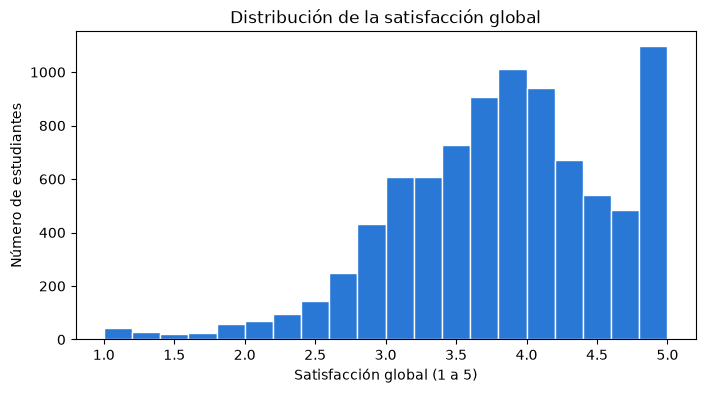

In [54]:
plt.figure(figsize=(8, 4))
plt.hist(datos["satisfaccion_global"], bins=20, color=azul, edgecolor="white")
plt.title("Distribución de la satisfacción global")
plt.xlabel("Satisfacción global (1 a 5)")
plt.ylabel("Número de estudiantes")
plt.savefig("img/01_histograma_satisfaccion.png", dpi=120, bbox_inches="tight")
plt.show()

### 8.2 Promedio por dimensión

In [55]:
promedios = datos[dimensiones].mean().sort_values()
promedios.round(2)

procesos_academicos        3.54
comedor                    3.58
bienestar_universitario    3.73
infraestructura            3.86
recursos_virtuales         3.87
responsabilidad_social     3.87
investigacion_formativa    3.89
tutoria                    3.91
evaluacion_aprendizaje     3.91
docentes                   3.95
plan_estudios              3.97
dtype: float64

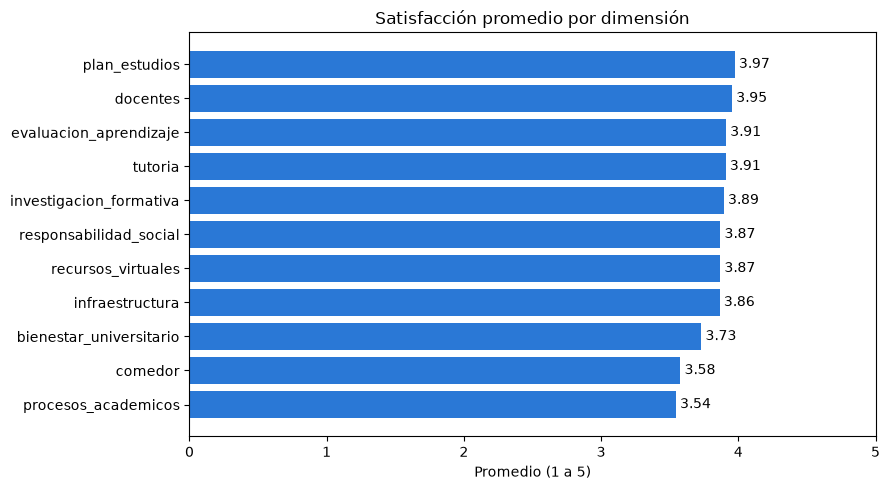

In [56]:
plt.figure(figsize=(9, 5))
barras = plt.barh(promedios.index, promedios.values, color=azul)
plt.bar_label(barras, fmt="%.2f", padding=3)
plt.xlim(0, 5)
plt.title("Satisfacción promedio por dimensión")
plt.xlabel("Promedio (1 a 5)")
plt.tight_layout()
plt.savefig("img/02_promedio_por_dimension.png", dpi=120, bbox_inches="tight")
plt.show()

### 8.3 Dimensiones por área de conocimiento
Un mapa de calor con la tabla de la sección 6: cuanto más oscuro el azul, mayor la satisfacción.

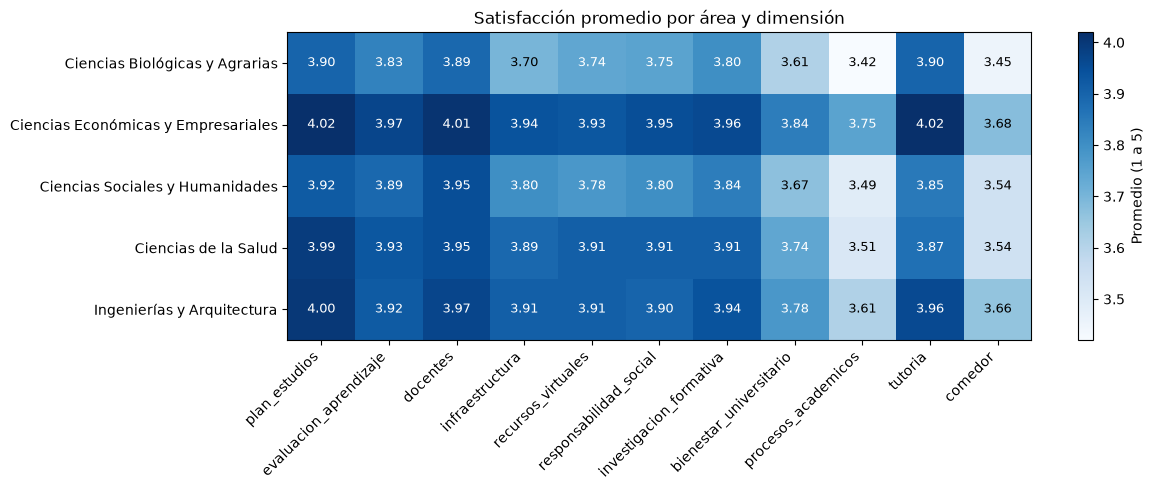

In [57]:
plt.figure(figsize=(12, 4))
plt.imshow(tabla_areas.values, cmap="Blues", aspect="auto")
plt.colorbar(label="Promedio (1 a 5)")
plt.xticks(range(len(dimensiones)), dimensiones, rotation=45, ha="right")
plt.yticks(range(len(tabla_areas.index)), tabla_areas.index)

mitad = (tabla_areas.values.min() + tabla_areas.values.max()) / 2
for fila in range(tabla_areas.shape[0]):
    for columna in range(tabla_areas.shape[1]):
        valor = tabla_areas.values[fila, columna]
        color_texto = "white" if valor > mitad else "black"
        plt.text(columna, fila, f"{valor:.2f}", ha="center", va="center", color=color_texto, fontsize=9)

plt.title("Satisfacción promedio por área y dimensión")
plt.savefig("img/03_mapa_calor_area_dimension.png", dpi=120, bbox_inches="tight")
plt.show()

### 8.4 Satisfacción global según la etapa de la carrera

In [58]:
etapas = ["Inicial", "Intermedia", "Final"]
grupos = [datos[datos["etapa_carrera"] == etapa]["satisfaccion_global"] for etapa in etapas]

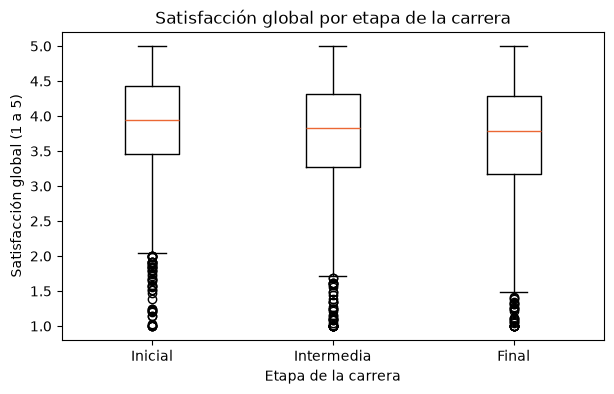

In [59]:
plt.figure(figsize=(7, 4))
plt.boxplot(grupos, medianprops={"color": naranja})
plt.xticks([1, 2, 3], etapas)
plt.title("Satisfacción global por etapa de la carrera")
plt.xlabel("Etapa de la carrera")
plt.ylabel("Satisfacción global (1 a 5)")
plt.savefig("img/04_cajas_etapa_carrera.png", dpi=120, bbox_inches="tight")
plt.show()

### 8.5 Estudiantes que pensaron en dejar la carrera
Comparamos el promedio de cada dimensión entre quienes respondieron que sí consideraron desertar y quienes respondieron que no. Solo entran los estudiantes que contestaron esa pregunta.

In [60]:
con_respuesta = datos.dropna(subset=["considero_desertar"])
con_respuesta["considero_desertar"].value_counts()

considero_desertar
No    3898
Si    1114
Name: count, dtype: int64

In [61]:
comparacion = con_respuesta.groupby("considero_desertar")[dimensiones].mean().T
comparacion["diferencia"] = comparacion["No"] - comparacion["Si"]
comparacion = comparacion.sort_values("diferencia")
comparacion.round(2)

considero_desertar,No,Si,diferencia
infraestructura,3.94,3.56,0.38
recursos_virtuales,3.95,3.51,0.43
docentes,4.03,3.58,0.45
evaluacion_aprendizaje,4.00,3.53,0.46
investigacion_formativa,3.98,3.50,0.48
comedor,3.70,3.21,0.49
bienestar_universitario,3.83,3.33,0.50
plan_estudios,4.06,3.56,0.50
responsabilidad_social,3.97,3.45,0.51
tutoria,3.99,3.45,0.54


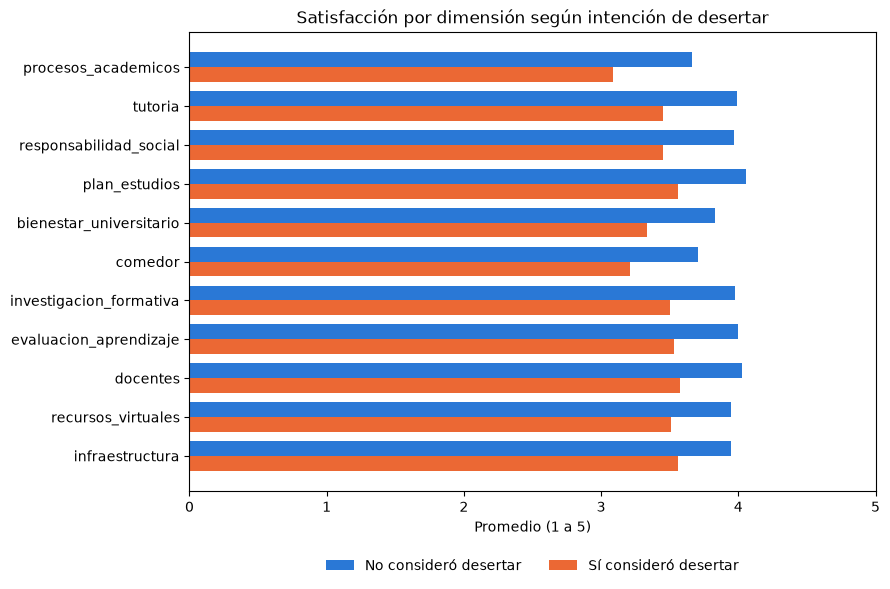

In [62]:
posicion = np.arange(len(comparacion))
alto = 0.38

plt.figure(figsize=(9, 6))
plt.barh(posicion + alto / 2, comparacion["No"], height=alto, color=azul, label="No consideró desertar")
plt.barh(posicion - alto / 2, comparacion["Si"], height=alto, color=naranja, label="Sí consideró desertar")
plt.yticks(posicion, comparacion.index)
plt.xlim(0, 5)
plt.title("Satisfacción por dimensión según intención de desertar")
plt.xlabel("Promedio (1 a 5)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("img/05_dimensiones_desercion.png", dpi=120, bbox_inches="tight")
plt.show()

### 8.6 Relación entre dos dimensiones

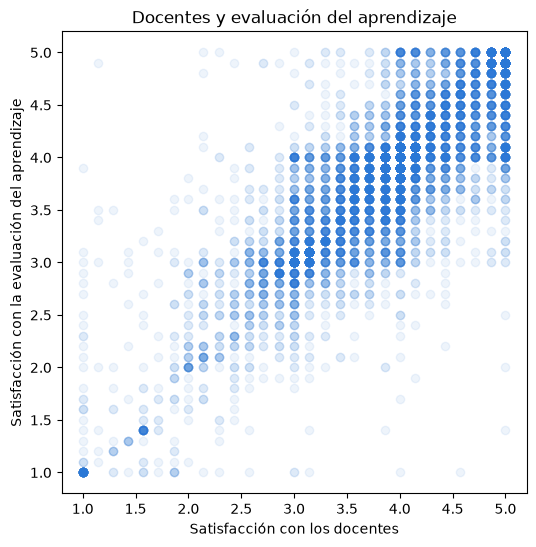

In [63]:
plt.figure(figsize=(6, 6))
plt.scatter(datos["docentes"], datos["evaluacion_aprendizaje"], alpha=.08, color=azul)
plt.title("Docentes y evaluación del aprendizaje")
plt.xlabel("Satisfacción con los docentes")
plt.ylabel("Satisfacción con la evaluación del aprendizaje")
plt.savefig("img/06_dispersion_docentes_evaluacion.png", dpi=120, bbox_inches="tight")
plt.show()

In [64]:
datos[["docentes", "evaluacion_aprendizaje"]].corr().round(2)

,docentes,evaluacion_aprendizaje
docentes,1.00,0.87
evaluacion_aprendizaje,0.87,1.00


## 9. Gráficos con Bokeh
Los gráficos de Bokeh son interactivos: al pasar el cursor sobre una barra se muestra su valor.

In [65]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
from bokeh.models import ColumnDataSource

In [66]:
output_notebook()

Loading BokehJS ...

### 9.1 Satisfacción global por área

In [67]:
resumen = datos.groupby("nombre_area", as_index=False).agg(
    satisfaccion=("satisfaccion_global", "mean"),
    estudiantes=("id_encuestado", "count"),
)

In [68]:
resumen = resumen.sort_values("satisfaccion", ascending=False)
resumen["satisfaccion"] = resumen["satisfaccion"].round(2)
resumen

,nombre_area,satisfaccion,estudiantes
1,Ciencias Económicas y Empresariales,3.92,572
4,Ingenierías y Arquitectura,3.87,2796
3,Ciencias de la Salud,3.83,2623
2,Ciencias Sociales y Humanidades,3.78,1927
0,Ciencias Biológicas y Agrarias,3.73,838


In [69]:
fuente = ColumnDataSource(resumen)

In [70]:
grafico = figure(
    x_range=resumen["nombre_area"].tolist(),
    y_range=(0, 5),
    title="Satisfacción global promedio por área de conocimiento",
    width=850, height=380,
    tooltips=[("Área", "@nombre_area"), ("Promedio", "@satisfaccion"), ("Estudiantes", "@estudiantes")],
)

In [71]:
grafico.vbar(x="nombre_area", top="satisfaccion", width=0.6, color=azul, source=fuente)

GlyphRenderer(id='p1052', ...)

In [72]:
grafico.xaxis.major_label_orientation = 0.4
grafico.yaxis.axis_label = "Satisfacción global (1 a 5)"
grafico.xgrid.grid_line_color = None

In [73]:
show(grafico)

### 9.2 Porcentaje que consideró desertar, por etapa de la carrera

In [74]:
con_etapa = con_respuesta[con_respuesta["etapa_carrera"].isin(etapas)].copy()
con_etapa["considero"] = np.where(con_etapa["considero_desertar"] == "Si", 1, 0)

In [75]:
desercion = con_etapa.groupby("etapa_carrera", as_index=False).agg(
    consideraron=("considero", "sum"),
    respondieron=("considero", "count"),
)
desercion["porcentaje"] = (desercion["consideraron"] / desercion["respondieron"] * 100).round(1)
desercion = desercion.set_index("etapa_carrera").loc[etapas].reset_index()
desercion

,etapa_carrera,consideraron,respondieron,porcentaje
0,Inicial,386,1947,19.8
1,Intermedia,422,1780,23.7
2,Final,299,1265,23.6


In [76]:
fuente2 = ColumnDataSource(desercion)

In [77]:
grafico2 = figure(
    x_range=etapas,
    y_range=(0, 40),
    title="Estudiantes que consideraron desertar, por etapa de la carrera",
    width=650, height=380,
    tooltips=[("Etapa", "@etapa_carrera"), ("Porcentaje", "@porcentaje %"), ("Respondieron", "@respondieron")],
)

In [78]:
grafico2.vbar(x="etapa_carrera", top="porcentaje", width=0.5, color=naranja, source=fuente2)

GlyphRenderer(id='p1106', ...)

In [79]:
grafico2.xaxis.axis_label = "Etapa de la carrera"
grafico2.yaxis.axis_label = "Porcentaje de estudiantes (%)"
grafico2.xgrid.grid_line_color = None

In [80]:
show(grafico2)